<a href="https://colab.research.google.com/github/mrmcgruder98/Assignment-2-PDS/blob/main/Assignment_2_part_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 25)

local_path = Path("data/Ass2 PDS D.csv")
data_url = "https://github.com/mrmcgruder98/Assignment-2-PDS/raw/refs/heads/main/Ass2%20PDS%20D.csv"
source = local_path if local_path.exists() else data_url

# Ensure output directory exists if loading locally in the future
if not local_path.exists():
    local_path.parent.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(source)
print(f"Dataset successfully loaded from: {source}")
print(f"Dataset Shape: {df_raw.shape}")

Dataset successfully loaded from: https://github.com/mrmcgruder98/Assignment-2-PDS/raw/refs/heads/main/Ass2%20PDS%20D.csv
Dataset Shape: (768, 9)


In [2]:

# Set random seed for reproducibility
np.random.seed(42)

# Take a random sample of 25 patients
sample_25 = df_raw.sample(n=25)

# Calculate statistics
sample_mean_glucose = sample_25['Glucose'].mean()
sample_max_glucose = sample_25['Glucose'].max()
population_max_glucose = df_raw['Glucose'].max()

print(f"--- Glucose Levels Analysis (Sample size: 25) ---")
print(f"Sample Mean Glucose: {sample_mean_glucose:.2f}")
print(f"Sample Maximum Glucose: {sample_max_glucose:.2f}")
print(f"Full Dataset Maximum Glucose: {population_max_glucose:.2f}\n")

# Display the sample dataframe
display(sample_25[['Glucose', 'Pregnancies', 'Age', 'Outcome']].head(10))


--- Glucose Levels Analysis (Sample size: 25) ---
Sample Mean Glucose: 116.64
Sample Maximum Glucose: 183.00
Full Dataset Maximum Glucose: 199.00



,Glucose,Pregnancies,Age,Outcome
668,98,6,43,0
324,112,2,21,0
624,108,2,21,0
690,107,8,34,0
473,136,7,50,0
204,103,6,55,0
97,71,1,22,0
336,117,0,44,0
568,154,4,37,0
148,147,5,65,0


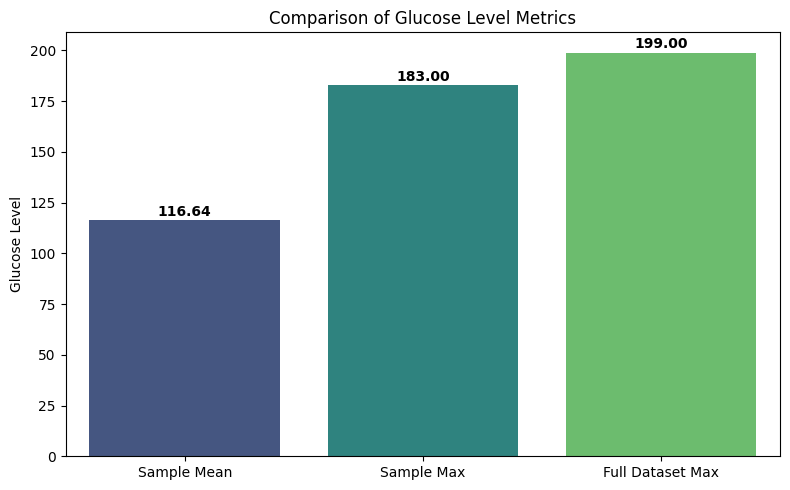

In [3]:
# Visualization comparing the statistics
fig, ax = plt.subplots(figsize=(8, 5))
metrics = ['Sample Mean', 'Sample Max', 'Full Dataset Max']
values = [sample_mean_glucose, sample_max_glucose, population_max_glucose]

sns.barplot(x=metrics, y=values, hue=metrics, palette='viridis', legend=False)
plt.title('Comparison of Glucose Level Metrics')
plt.ylabel('Glucose Level')
for i, v in enumerate(values):
    ax.text(i, v + 2, f"{v:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [4]:
# Calculate the 98th percentile of BMI for the sample and the population
sample_98th_bmi = np.percentile(sample_25['BMI'], 98)
population_98th_bmi = np.percentile(df_raw['BMI'], 98)

print(f"--- 98th Percentile of BMI ---")
print(f"Sample (n=25) 98th Percentile: {sample_98th_bmi:.2f}")
print(f"Population (n=768) 98th Percentile: {population_98th_bmi:.2f}")

--- 98th Percentile of BMI ---
Sample (n=25) 98th Percentile: 40.25
Population (n=768) 98th Percentile: 47.53


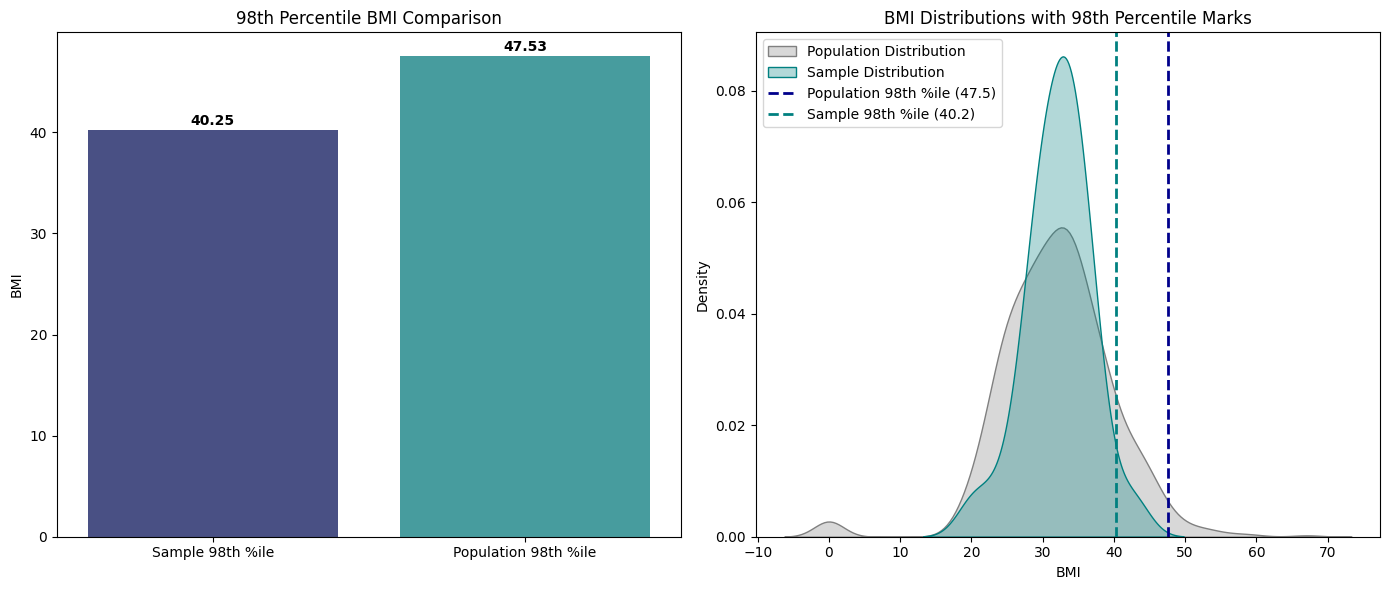

In [5]:
# Create visualizations comparing the 98th percentile
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Bar Chart Comparison
metrics = ['Sample 98th %ile', 'Population 98th %ile']
values = [sample_98th_bmi, population_98th_bmi]
sns.barplot(x=metrics, y=values, hue=metrics, palette='mako', ax=axes[0], legend=False)
axes[0].set_title('98th Percentile BMI Comparison')
axes[0].set_ylabel('BMI')
for i, v in enumerate(values):
    axes[0].text(i, v + 0.5, f"{v:.2f}", ha='center', fontweight='bold')

# Subplot 2: Distribution Chart
sns.kdeplot(data=df_raw, x='BMI', fill=True, color='gray', alpha=0.3, label='Population Distribution', ax=axes[1])
sns.kdeplot(data=sample_25, x='BMI', fill=True, color='teal', alpha=0.3, label='Sample Distribution', ax=axes[1])
axes[1].axvline(population_98th_bmi, color='darkblue', linestyle='--', linewidth=2, label=f'Population 98th %ile ({population_98th_bmi:.1f})')
axes[1].axvline(sample_98th_bmi, color='teal', linestyle='--', linewidth=2, label=f'Sample 98th %ile ({sample_98th_bmi:.1f})')
axes[1].set_title('BMI Distributions with 98th Percentile Marks')
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
# Perform bootstrapping
np.random.seed(42)
n_iterations = 500
sample_size = 150

# Initialize lists to store bootstrap statistics
bootstrap_means = []
bootstrap_stds = []
bootstrap_95th_percentiles = []

for _ in range(n_iterations):
    # Sample with replacement
    boot_sample = df_raw['BloodPressure'].sample(n=sample_size, replace=True)
    bootstrap_means.append(boot_sample.mean())
    bootstrap_stds.append(boot_sample.std())
    bootstrap_95th_percentiles.append(np.percentile(boot_sample, 95))

# Calculate population statistics
pop_mean = df_raw['BloodPressure'].mean()
pop_std = df_raw['BloodPressure'].std()
pop_95th = np.percentile(df_raw['BloodPressure'], 95)

# Calculate average of the bootstrap statistics
boot_mean_avg = np.mean(bootstrap_means)
boot_std_avg = np.mean(bootstrap_stds)
boot_95th_avg = np.mean(bootstrap_95th_percentiles)

print(f"--- BloodPressure Statistics Comparison ---")
print(f"Population Mean: {pop_mean:.2f} | Bootstrap Avg Mean: {boot_mean_avg:.2f}")
print(f"Population Std Dev: {pop_std:.2f} | Bootstrap Avg Std Dev: {boot_std_avg:.2f}")
print(f"Population 95th Percentile: {pop_95th:.2f} | Bootstrap Avg 95th Percentile: {boot_95th_avg:.2f}")

--- BloodPressure Statistics Comparison ---
Population Mean: 69.11 | Bootstrap Avg Mean: 69.18
Population Std Dev: 19.36 | Bootstrap Avg Std Dev: 19.07
Population 95th Percentile: 90.00 | Bootstrap Avg 95th Percentile: 91.13


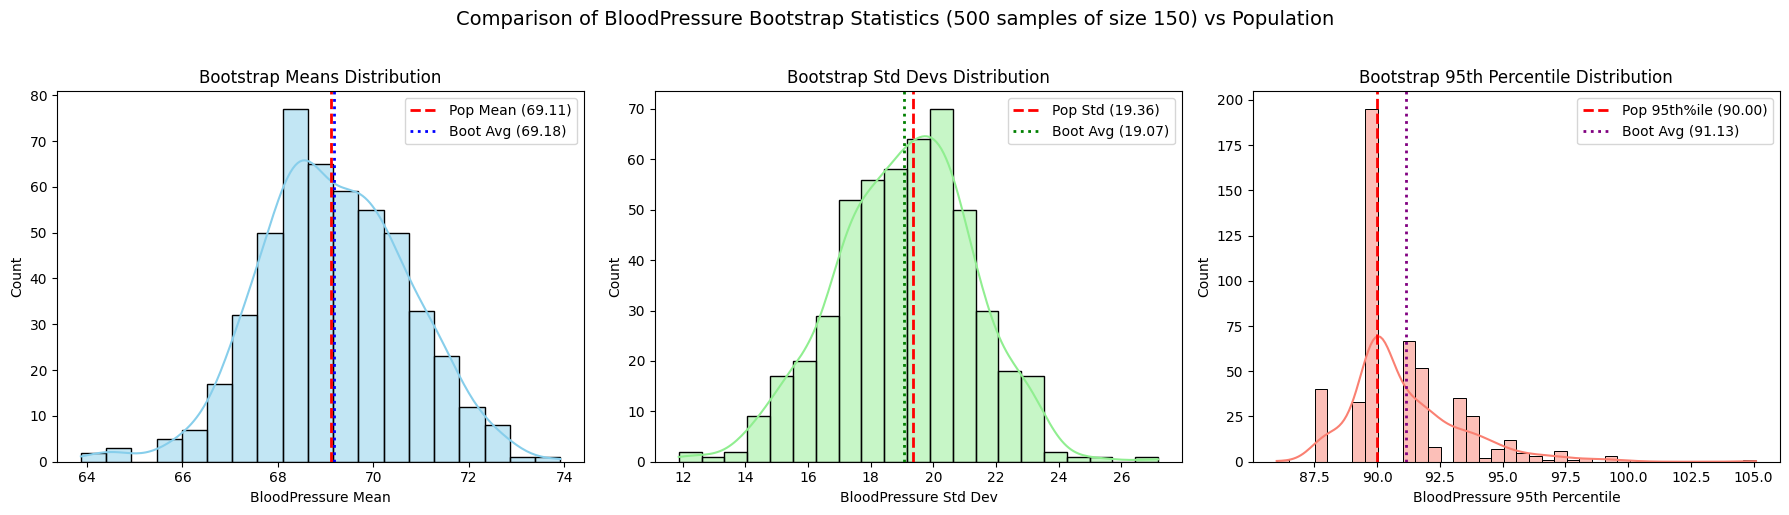

In [8]:
# Create visualizations for Bootstrap vs Population Stat
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Mean Distribution
sns.histplot(bootstrap_means, kde=True, color='skyblue', ax=axes[0])
axes[0].axvline(pop_mean, color='red', linestyle='--', linewidth=2, label=f'Pop Mean ({pop_mean:.2f})')
axes[0].axvline(boot_mean_avg, color='blue', linestyle=':', linewidth=2, label=f'Boot Avg ({boot_mean_avg:.2f})')
axes[0].set_title('Bootstrap Means Distribution')
axes[0].set_xlabel('BloodPressure Mean')
axes[0].legend()

# 2. Standard Deviation
sns.histplot(bootstrap_stds, kde=True, color='lightgreen', ax=axes[1])
axes[1].axvline(pop_std, color='red', linestyle='--', linewidth=2, label=f'Pop Std ({pop_std:.2f})')
axes[1].axvline(boot_std_avg, color='green', linestyle=':', linewidth=2, label=f'Boot Avg ({boot_std_avg:.2f})')
axes[1].set_title('Bootstrap Std Devs Distribution')
axes[1].set_xlabel('BloodPressure Std Dev')
axes[1].legend()

# 3. Percentile Distribution
sns.histplot(bootstrap_95th_percentiles, kde=True, color='salmon', ax=axes[2])
axes[2].axvline(pop_95th, color='red', linestyle='--', linewidth=2, label=f'Pop 95th%ile ({pop_95th:.2f})')
axes[2].axvline(boot_95th_avg, color='purple', linestyle=':', linewidth=2, label=f'Boot Avg ({boot_95th_avg:.2f})')
axes[2].set_title('Bootstrap 95th Percentile Distribution')
axes[2].set_xlabel('BloodPressure 95th Percentile')
axes[2].legend()

plt.suptitle('Comparison of BloodPressure Bootstrap Statistics (500 samples of size 150) vs Population', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()